# Notebook B: chia dữ liệu, mô hình, câu hỏi thứ ba và giải thích

**Đề tài:** Chọn vị trí đeo cảm biến cho nhận dạng hoạt động bằng lời giải thích được kiểm chứng qua huấn luyện lại trên MHEALTH với mười mô hình

**Sinh viên B** chạy sau khi Notebook A đã tạo file parquet, `sql/queries.sql` và `manifest.json`. Notebook này không cần kernel của Notebook A.

> **Cập nhật 12/11/2026 (bản sửa SOFTT 2026, bài #1571376950):** thí nghiệm vị trí đeo chạy với ba mô hình (LightGBM, Extra Trees, XGBoost) và ba seed; ROAR lặp trên năm cách chia người với hai mô hình; thêm kiểm định tương đương (TOST, biên 0.03), mốc chọn vị trí bằng mutual information, ô ghi phần cứng và hình vị trí đeo mới. Các phần này thay cho phần cũ chỉ dùng LightGBM và một cách chia.


## Kiểm tra bàn giao

- **Làm gì:** đọc manifest và so mã băm của file parquet.
- **Vì sao:** bảo đảm hai notebook dùng đúng cùng một dữ liệu.
- **Kiểm tra:** ô in `handover ok`.

In [1]:
# run once per machine, then comment out and RESTART THE KERNEL before running the next cells
# %pip install -r requirements.txt
import os, json, hashlib, numpy as np, pandas as pd
with open('data/processed/manifest.json', encoding='utf-8') as f: m = json.load(f)
with open(m['file'], 'rb') as f: md5 = hashlib.md5(f.read()).hexdigest()
assert md5 == m['md5'], 'parquet differs from the manifest, rerun Notebook A'
os.makedirs('report', exist_ok=True); print('handover ok', m['rows'], 'rows')

handover ok 33148 rows


### Phần cứng đo thời gian

- **Làm gì:** in và lưu CPU, RAM, hệ điều hành, phiên bản thư viện vào `report/hardware.json`.
- **Vì sao:** cột `train_s` và `ms_per_window` ở RQ2 chỉ có nghĩa khi biết đo trên máy nào (reviewer 2 hỏi điều này).
- **Kiểm tra:** chạy ô này **trên đúng máy đã chạy ô RQ2** rồi chép một câu vào mục Evaluation của bài, ví dụ *"Times were measured on <CPU>, <RAM> GB RAM, <OS>, Python <x.y>."*

In [ ]:
import sys, platform, sklearn, lightgbm, xgboost, scipy
def ram_gb():
    try:
        import psutil; return round(psutil.virtual_memory().total / 2**30, 1)
    except ImportError: pass
    if os.name == 'nt':                                   # Windows without psutil
        import ctypes
        class M(ctypes.Structure): _fields_ = [('l', ctypes.c_ulong), ('m', ctypes.c_ulong)] + [(n, ctypes.c_ulonglong) for n in ['t', 'a', 'tp', 'ap', 'tv', 'av', 'e']]
        s = M(); s.l = ctypes.sizeof(M); ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(s)); return round(s.t / 2**30, 1)
    with open('/proc/meminfo') as f: return round(int(f.read().split()[1]) / 2**20, 1)
def cpu_name():
    if os.name == 'nt':
        try:
            import winreg; k = winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r'HARDWARE\DESCRIPTION\System\CentralProcessor\0')
            return winreg.QueryValueEx(k, 'ProcessorNameString')[0].strip()
        except OSError: pass
    try:
        with open('/proc/cpuinfo') as f: return next(l.split(':', 1)[1].strip() for l in f if l.startswith('model name'))
    except Exception: return platform.processor()
hw = {'cpu': cpu_name(), 'logical_cores': os.cpu_count(), 'ram_gb': ram_gb(), 'os': platform.platform(), 'python': sys.version.split()[0],
      'scikit-learn': sklearn.__version__, 'lightgbm': lightgbm.__version__, 'xgboost': xgboost.__version__, 'pandas': pd.__version__}
with open('report/hardware.json', 'w', encoding='utf-8') as f: json.dump(hw, f, indent=2)
print(json.dumps(hw, indent=2))

## Bước 4. Bảng đặc trưng và chia dữ liệu

- **Làm gì:** chạy lại `sql/queries.sql`, lấy bảng `feat`. RQ2 và phần vị trí đeo của RQ3 dùng leave-one-subject-out (LOSO): mỗi lần để riêng một trong 10 người làm tập kiểm thử. Phần ROAR của RQ3 giữ một cách chia cố định (người 8, 9, 10 làm kiểm thử) vì cần cùng một mô hình cho năm phương pháp giải thích.
- **Vì sao:** với một tập kiểm thử cố định, độ lệch chuẩn giữa các seed chỉ đo nhiễu của mô hình (gần 0), không đo khác biệt giữa người, mà khác biệt giữa người mới là nguồn sai số chính. Kiểm tra ổn định xếp hạng cần hai nhóm người không trùng nhau ({1, 2, 3} và {4, 5, 6, 7}).
- **Kiểm tra:** các dòng `assert` là phép kiểm tra rò rỉ và kiểm tra hai nhóm người tách rời; ghi số dòng hai tập và số đặc trưng vào bảng mô tả thực nghiệm.

In [3]:
# Step 4: split by person. RQ2 uses leave-one-subject-out over all 10 people; RQ3 (ROAR) keeps one fixed split
import duckdb
con = duckdb.connect()
with open('sql/queries.sql', encoding='utf-8') as f: con.execute(f.read())
feat = con.execute("SELECT * FROM feat").df()
X_cols = [c for c in feat.columns if c not in ['subject', 'run', 'win', 'activity']]
people = sorted(feat.subject.unique()); TEST_SUBJECTS = people[-3:]
assert all(set(feat[feat.subject == s].activity) == set(feat.activity) for s in people), 'every person has every activity'
classes = sorted(feat.activity.unique()); code = {c: i for i, c in enumerate(classes)}
X_all, y_all, subj = feat[X_cols], feat.activity.map(code), feat.subject.to_numpy()      # all people, for LOSO
train = feat[~feat.subject.isin(TEST_SUBJECTS)]; test = feat[feat.subject.isin(TEST_SUBJECTS)]
X_tr, y_tr, X_te, y_te = train[X_cols], train.activity.map(code), test[X_cols], test.activity.map(code)
GROUP = pd.Series(X_cols, index=X_cols).str.split('_').str[0].replace({'ecg': 'heart signal'})   # body position
GRP_A = train.subject.isin(people[:3]).to_numpy()        # two disjoint sets of training people for the stability check
GRP_B = train.subject.isin(people[3:7]).to_numpy()
assert set(train.subject).isdisjoint(test.subject)      # leakage check
assert set(train.subject[GRP_A]).isdisjoint(train.subject[GRP_B])
print(len(train), len(test), len(X_cols), 'features', len(classes), 'classes')

23355 9793 42 features 12 classes


## Bước 6a. So sánh mô hình (RQ2)

- **Làm gì:** huấn luyện mười mô hình và mốc naive (đoán lớp nhiều nhất) với leave-one-subject-out trên 10 người; seed đổi theo từng lần để riêng một người (seed 0 đến 9).
- **Vì sao:** so nhiều họ mô hình để kết luận không phụ thuộc một kiểu mô hình; độ lệch chuẩn giữa 10 người cho biết kết quả dao động bao nhiêu khi gặp người mới; mốc naive cho biết cải thiện là thật.
- **Kiểm tra:** chênh lệch nhỏ hơn độ lệch chuẩn thì chưa được kết luận mô hình nào hơn; kiểm định Wilcoxon theo cặp trên 10 người cho hai mô hình đứng đầu. Bảng lưu ở `report/table_rq2.csv`, điểm từng người ở `report/table_rq2_folds.csv`.
- **Ghi chú:** nếu `report/table_rq2_folds.csv` đã có, ô đọc lại bảng đó thay vì huấn luyện lại (giữ nguyên thời gian đo trên máy cũ). Đặt `RERUN_RQ2 = True` để chạy lại từ đầu.


In [4]:
# Step 6a: ten classifiers from four families plus a naive baseline, leave-one-subject-out over 10 people
import numpy as np, pandas as pd, time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, accuracy_score
from scipy.stats import wilcoxon
sc = lambda m: make_pipeline(StandardScaler(), m)       # scaling for linear, distance and neural models
models = {
    'Majority (naive)': lambda s: DummyClassifier(),
    'Logistic':       lambda s: sc(LogisticRegression(max_iter=500, random_state=s)),
    'Linear SVM':     lambda s: sc(LinearSVC(C=1.0, random_state=s)),
    'k-NN':           lambda s: sc(KNeighborsClassifier(n_neighbors=15)),
    'Decision Tree':  lambda s: DecisionTreeClassifier(max_depth=12, min_samples_leaf=5, random_state=s),
    'Random Forest':  lambda s: RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=s),
    'Extra Trees':    lambda s: ExtraTreesClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=s),
    'HistGB':         lambda s: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=s),
    'LightGBM':       lambda s: LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
                                               subsample_freq=1, colsample_bytree=0.8, random_state=s, verbose=-1),
    'XGBoost':        lambda s: XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8,
                                              colsample_bytree=0.8, tree_method='hist', random_state=s),
    'Small MLP':      lambda s: sc(MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=200, early_stopping=True,
                                                 random_state=s)),
}
RERUN_RQ2 = False
if os.path.exists('report/table_rq2_folds.csv') and not RERUN_RQ2:
    folds = pd.read_csv('report/table_rq2_folds.csv'); print('loaded report/table_rq2_folds.csv (set RERUN_RQ2 = True to retrain)')
else:
    folds = []
    for name, make in models.items():
        for i, s_out in enumerate(people):                  # leave one subject out; the seed changes with the fold
            tr, te = subj != s_out, subj == s_out
            m = make(i); t0 = time.perf_counter(); m.fit(X_all[tr], y_all[tr]); sec = time.perf_counter() - t0
            t0 = time.perf_counter(); p = m.predict(X_all[te]); ms = (time.perf_counter() - t0) / te.sum() * 1000
            folds.append([name, s_out, i, f1_score(y_all[te], p, average='macro'), accuracy_score(y_all[te], p), sec, ms])
    folds = pd.DataFrame(folds, columns=['model', 'held_out', 'seed', 'macroF1', 'accuracy', 'train_s', 'ms_per_window'])
res = folds.groupby('model', sort=False).agg(macroF1=('macroF1', 'mean'), sd=('macroF1', 'std'), worst_person=('macroF1', 'min'),
      accuracy=('accuracy', 'mean'), train_s=('train_s', 'mean'), ms_per_window=('ms_per_window', 'mean')).reset_index()
folds.to_csv('report/table_rq2_folds.csv', index=False); res.to_csv('report/table_rq2.csv', index=False); print(res.round(4))
per_person = folds.pivot(index='held_out', columns='model', values='macroF1'); print(per_person.round(3))
top2 = res.sort_values('macroF1', ascending=False).model.iloc[:2].tolist()     # is the leader really better than the runner-up?
print(top2, 'paired Wilcoxon over 10 people, p =', round(wilcoxon(per_person[top2[0]], per_person[top2[1]]).pvalue, 3))

loaded report/table_rq2_folds.csv (set RERUN_RQ2 = True to retrain)
               model  macroF1      sd  worst_person  accuracy  train_s  \
0   Majority (naive)   0.0138  0.0004        0.0133    0.0900   0.0077   
1           Logistic   0.9553  0.0425        0.8838    0.9633   0.5047   
2         Linear SVM   0.9435  0.0683        0.7943    0.9518   1.4768   
3               k-NN   0.9125  0.0597        0.8380    0.9294   0.0366   
4      Decision Tree   0.8930  0.0724        0.7862    0.9062   1.0158   
5      Random Forest   0.9504  0.0557        0.8462    0.9537   7.2972   
6        Extra Trees   0.9624  0.0482        0.8734    0.9673   1.1475   
7             HistGB   0.9513  0.0486        0.8775    0.9553   4.4104   
8           LightGBM   0.9327  0.0530        0.8548    0.9387   5.7447   
9            XGBoost   0.9579  0.0501        0.8687    0.9614   8.9393   
10         Small MLP   0.9269  0.0471        0.8707    0.9398   2.3846   

    ms_per_window  
0          0.0003  
1  

### Hình RQ2

- **Làm gì:** vẽ kết quả các mô hình, tô màu nhấn mô hình tốt nhất.
- **Kiểm tra:** số trên cột khớp với `report/table_rq2.csv`.

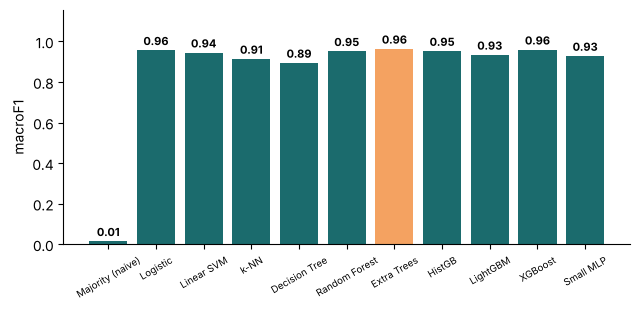

In [5]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30)
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

bar_chart(res.model, res.iloc[:, 1], res.columns[1], 'report/fig_rq2_models.png', highlight=int(res.iloc[:, 1].idxmax()), fmt='{:.2f}')

### Ý nghĩa thống kê và ý nghĩa thực tế giữa các mô hình

- **Làm gì:** với từng cặp trong năm mô hình đứng đầu, lấy hiệu macro-F1 của từng người, tính khoảng tin cậy 95%, Wilcoxon và **TOST** (hai kiểm định t một phía) với biên tương đương ±0.03.
- **Vì sao:** với 10 người, "Wilcoxon không có ý nghĩa" không có nghĩa là "bằng nhau". TOST hỏi thẳng: chênh lệch có nằm trong ±0.03 không. Biên 0.03 là ngưỡng bài đã nêu (nhỏ hơn độ lệch chuẩn giữa người, khoảng 0.05).
- **Kiểm tra:** cột `verdict`: `equivalent (±0.03)` nếu TOST p < 0.05; `different` nếu Wilcoxon p < 0.05 và khoảng tin cậy không chứa 0; còn lại `unresolved`. Bảng lưu ở `report/table_rq2_tests.csv`.

In [6]:
from scipy import stats
import itertools
MARGIN = 0.03                                            # practical threshold stated in the paper
def compare(d):                                          # d: paired differences over the ten people
    d = np.asarray(d, float); n = len(d); mu = d.mean(); se = d.std(ddof=1) / np.sqrt(n); tq = stats.t.ppf(0.975, n - 1)
    p_tost = max(1 - stats.t.cdf((mu + MARGIN) / se, n - 1), stats.t.cdf((mu - MARGIN) / se, n - 1))
    p_w = stats.wilcoxon(d).pvalue if np.any(d != 0) else 1.0
    lo, hi = mu - tq * se, mu + tq * se
    verdict = 'equivalent (±0.03)' if p_tost < 0.05 else ('different' if p_w < 0.05 and (lo > 0 or hi < 0) else 'unresolved')
    return dict(mean_diff=mu, ci_low=lo, ci_high=hi, wilcoxon_p=p_w, tost_p=p_tost, verdict=verdict)
top5 = res.sort_values('macroF1', ascending=False).model.iloc[:5].tolist()
rq2_tests = pd.DataFrame([{'pair': f'{a} - {b}', **compare(per_person[a] - per_person[b])} for a, b in itertools.combinations(top5, 2)])
rq2_tests.to_csv('report/table_rq2_tests.csv', index=False); print(rq2_tests.round(4).to_string(index=False))

                       pair  mean_diff  ci_low  ci_high  wilcoxon_p  tost_p            verdict
      Extra Trees - XGBoost     0.0045 -0.0251   0.0341      0.9453  0.0416 equivalent (±0.03)
     Extra Trees - Logistic     0.0071 -0.0044   0.0186      0.2754  0.0008 equivalent (±0.03)
       Extra Trees - HistGB     0.0111 -0.0178   0.0401      0.6523  0.0873         unresolved
Extra Trees - Random Forest     0.0120 -0.0023   0.0263      0.1289  0.0095 equivalent (±0.03)
         XGBoost - Logistic     0.0026 -0.0294   0.0347      0.4316  0.0426 equivalent (±0.03)
           XGBoost - HistGB     0.0066 -0.0293   0.0426      1.0000  0.0878         unresolved
    XGBoost - Random Forest     0.0075 -0.0184   0.0334      1.0000  0.0405 equivalent (±0.03)
          Logistic - HistGB     0.0040 -0.0271   0.0351      1.0000  0.0456 equivalent (±0.03)
   Logistic - Random Forest     0.0049 -0.0166   0.0264      0.9219  0.0134 equivalent (±0.03)
     HistGB - Random Forest     0.0008 -0.0309   0

## Bước 6b. Câu hỏi thứ ba (RQ3)

- **Làm gì:** năm phương pháp giải thích (TreeSHAP, KernelSHAP, LIME viết tay, permutation, split gain/impurity) được kiểm chứng theo bốn phần: (1) ROAR trên **năm cách chia người** với **LightGBM và Extra Trees**; (2) huấn luyện lại khi bỏ hoặc giữ vị trí đeo với **LightGBM, Extra Trees, XGBoost** và **ba seed** (leave-one-subject-out); (3) mốc chọn vị trí không cần huấn luyện (mutual information); (4) ổn định xếp hạng giữa hai nhóm người.
- **Vì sao:** bản nộp chỉ dùng LightGBM (hạng 7/10 ở RQ2) và một cách chia; cả hai reviewer yêu cầu kiểm tra kết luận với mô hình mạnh hơn và nhiều cách chia hơn. Thiết bị ở ngực gồm cả gia tốc và hai đạo trình ECG, nên "bỏ ngực" bỏ cả hai.
- **Kiểm tra:** hàng Random phải ít hại hơn các phương pháp giải thích khi che; chênh lệch nhỏ hơn độ lệch chuẩn giữa các cách chia thì chưa kết luận phương pháp nào trung thực hơn. Các ô lưu kết quả ngay sau từng bước, nên bị ngắt thì chạy lại ô đó, phần đã xong được bỏ qua; xoá file CSV tương ứng để chạy lại từ đầu.

In [7]:
# Step 6b-0: explanation methods for any fitted model; background and scales come from that model's training people
import shap
from sklearn.linear_model import Ridge
from sklearn.inspection import permutation_importance
from scipy.stats import spearmanr
MODELS3 = {name: models[name] for name in ['LightGBM', 'Extra Trees', 'XGBoost']}       # same hyperparameters as RQ2
def fit_best(X, y, seed=0, name='LightGBM'): return MODELS3[name](seed).fit(X, y)
def pool(sv):                                            # mean absolute attribution per feature, classes pooled
    if isinstance(sv, list): sv = np.stack(sv, axis=-1)                 # older shap returns one array per class
    sv = np.abs(np.asarray(sv)); return sv.mean(axis=0) if sv.ndim == 2 else sv.mean(axis=(0, 2))
def r_tree_shap(m, Xtr, X, y, n=200): return pool(shap.TreeExplainer(m).shap_values(X.sample(min(n, len(X)), random_state=0)))
def r_kernel_shap(m, Xtr, X, y, n=50):                   # model-agnostic SHAP, 20 k-means background points
    np.random.seed(0)                                    # KernelSHAP samples coalitions with numpy's global generator
    f = lambda Z: m.predict_proba(pd.DataFrame(Z, columns=X.columns))
    return pool(shap.KernelExplainer(f, shap.kmeans(Xtr[X.columns], 20)).shap_values(X.sample(n, random_state=0), nsamples=300, silent=True))
def r_lime(m, Xtr, X, y, n=50, n_pert=500):              # LIME procedure (Ribeiro et al., 2016) written out, no extra package
    f = lambda Z: m.predict_proba(pd.DataFrame(Z, columns=X.columns))
    rs = np.random.RandomState(0); sd = Xtr[X.columns].std().to_numpy() + 1e-9; w = np.zeros(X.shape[1])
    for x in X.sample(n, random_state=0).to_numpy():
        Z = x + rs.randn(n_pert, len(x)) * sd; p = f(Z)[:, f(x[None]).argmax()]          # probability of the predicted class
        d = np.sqrt((((Z - x) / sd) ** 2).sum(1)); k = np.exp(-d ** 2 / (0.75 * np.sqrt(len(x))) ** 2)
        w += np.abs(Ridge(alpha=1.0).fit((Z - x) / sd, p, sample_weight=k).coef_)    # weighted local linear surrogate
    return w / n
def r_perm(m, Xtr, X, y, n=3000):                        # loss of score when one feature is shuffled
    Xv = X.sample(min(n, len(X)), random_state=0)
    return permutation_importance(m, Xv, y.loc[Xv.index], n_repeats=3, scoring='f1_macro', random_state=0).importances_mean
def r_gain(m, Xtr, X, y):                                # split gain of LightGBM, impurity decrease of a forest
    return m.booster_.feature_importance('gain') if hasattr(m, 'booster_') else m.feature_importances_
METHODS = {'TreeSHAP': r_tree_shap, 'KernelSHAP': r_kernel_shap, 'LIME': r_lime, 'Permutation': r_perm, 'Gain': r_gain}
def explain_all(m, Xtr, X, y):                           # one ranking per method plus the time each one takes
    R, secs = {}, {}
    for name, f in METHODS.items():
        t0 = time.perf_counter(); R[name] = pd.Series(f(m, Xtr, X, y), index=X.columns).sort_values(ascending=False)
        secs[name] = time.perf_counter() - t0
    return R, secs
def f1(m, X, y): return f1_score(y, m.predict(X), average='macro')
print('methods ready:', list(METHODS), '| models:', list(MODELS3))

methods ready: ['TreeSHAP', 'KernelSHAP', 'LIME', 'Permutation', 'Gain'] | models: ['LightGBM', 'Extra Trees', 'XGBoost']


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 6b-1. ROAR: che hay huấn luyện lại, năm cách chia, hai mô hình

- **Làm gì:** cách chia 0 là cách chia cũ (người 8, 9, 10 kiểm thử) và giữ đường cong k = 1, 3, 6, 10 với LightGBM và ba seed như bản nộp (`report/table_rq3_roar.csv`). Thêm bốn cách chia 7/3 người khác (chọn ngẫu nhiên, seed 2026) và Extra Trees; ở mọi cách chia, mười đặc trưng đứng đầu được che bằng trung bình tập huấn luyện (masking) hoặc bỏ đi rồi huấn luyện lại (retraining).
- **Kiểm tra:** `report/table_rq3_roar_summary.csv`: cột `splits_gap_over_0_1` đếm số cách chia mà huấn luyện lại cao hơn che ít nhất 0.1.

In [8]:
# Step 6b-1: ROAR on five person splits and two models (k = 10), plus the original k-curve on split 0 with LightGBM
SEEDS = [0, 1, 2]
rs = np.random.RandomState(2026); others = [c for c in itertools.combinations(people, 3) if set(c) != set(TEST_SUBJECTS)]
SPLITS = [tuple(TEST_SUBJECTS)] + [others[i] for i in rs.choice(len(others), 4, replace=False)]
KS = [1, 3, 6, 10]
path = 'report/table_rq3_roar_splits.csv'
roar_rows = pd.read_csv(path) if os.path.exists(path) else pd.DataFrame(columns=['split', 'test_people', 'model', 'method', 'k', 'seeds', 'base', 'masked', 'retrained', 'retrained_sd'])
for i, tp in enumerate(SPLITS):
    te_mask = feat.subject.isin(tp).to_numpy(); Xa, ya, Xb, yb = X_all[~te_mask], y_all[~te_mask], X_all[te_mask], y_all[te_mask]
    for mname in ['LightGBM', 'Extra Trees']:
        curve = (i == 0 and mname == 'LightGBM')                       # the original experiment, kept for comparison
        if ((roar_rows.split == i) & (roar_rows.model == mname)).any(): continue
        t0 = time.perf_counter(); seeds = SEEDS if curve else [0]
        m = fit_best(Xa, ya, 0, mname); base = np.mean([f1(fit_best(Xa, ya, s, mname), Xb, yb) for s in seeds])
        R, _ = explain_all(m, Xa, Xb, yb)
        R['Random'] = pd.Series(np.random.RandomState(i).rand(len(X_cols)), index=X_cols).sort_values(ascending=False)
        new = []
        for meth, r in R.items():
            for k in (KS if curve else [10]):
                top = list(r.index[:k]); keep = [c for c in X_cols if c not in top]
                Xp = Xb.copy(); Xp[top] = Xa[top].mean().values
                rt = [f1(fit_best(Xa[keep], ya, s, mname), Xb[keep], yb) for s in seeds]
                new.append([i, ' '.join(map(str, tp)), mname, meth, k, len(seeds), base, f1(m, Xp, yb), np.mean(rt), np.std(rt)])
        roar_rows = pd.concat([roar_rows, pd.DataFrame(new, columns=roar_rows.columns)], ignore_index=True); roar_rows.to_csv(path, index=False)
        print(f'split {i} test people {tp} {mname:12s} base {base:.3f} ({time.perf_counter() - t0:.0f} s)')
roar = roar_rows[(roar_rows.split == 0) & (roar_rows.model == 'LightGBM')].rename(columns={'masked': 'deleted'})
roar[['method', 'k', 'deleted', 'retrained', 'retrained_sd']].to_csv('report/table_rq3_roar.csv', index=False)   # same layout as before
base = roar.base.iloc[0]; print('split 0, LightGBM, all features', round(base, 3))
print(roar.pivot(index='method', columns='k', values='retrained').round(3))
r10 = roar_rows[roar_rows.k == 10].assign(gap=lambda d: d.retrained - d.masked)
roar_sum = r10.groupby(['model', 'method']).agg(base=('base', 'mean'), masked_mean=('masked', 'mean'), masked_sd=('masked', 'std'),
              retrained_mean=('retrained', 'mean'), retrained_sd=('retrained', 'std'), gap_mean=('gap', 'mean'),
              splits_gap_over_0_1=('gap', lambda g: int((g > 0.1).sum()))).reset_index()
roar_sum.to_csv('report/table_rq3_roar_summary.csv', index=False); print('splits:', SPLITS); print(roar_sum.round(3).to_string(index=False))
# rankings of split 0 with LightGBM feed the share table, step 6c and the stability check
best = fit_best(X_tr, y_tr); ranks, secs = explain_all(best, X_tr, X_te, y_te)
ranks['Random'] = pd.Series(np.random.RandomState(0).rand(len(X_cols)), index=X_cols).sort_values(ascending=False)

split 0, LightGBM, all features 0.947
k               1      3      6      10
method                                 
Gain         0.949  0.939  0.946  0.944
KernelSHAP   0.940  0.937  0.924  0.923
LIME         0.940  0.937  0.951  0.956
Permutation  0.940  0.937  0.944  0.905
Random       0.948  0.947  0.948  0.951
TreeSHAP     0.940  0.937  0.923  0.930
splits: [(np.int64(8), np.int64(9), np.int64(10)), (np.int64(1), np.int64(3), np.int64(6)), (np.int64(2), np.int64(3), np.int64(7)), (np.int64(5), np.int64(6), np.int64(10)), (np.int64(2), np.int64(9), np.int64(10))]
      model      method  base  masked_mean  masked_sd  retrained_mean  retrained_sd  gap_mean  splits_gap_over_0_1
Extra Trees        Gain 0.956        0.357      0.045           0.900         0.068     0.542                    5
Extra Trees  KernelSHAP 0.956        0.241      0.069           0.903         0.044     0.662                    5
Extra Trees        LIME 0.956        0.236      0.058           0.909         0.

### 6b-2. Vị trí đeo: bỏ hoặc giữ một vị trí, ba mô hình, ba seed

- **Làm gì:** tỷ trọng giải thích theo vị trí (như bản nộp), rồi huấn luyện lại trên từng tổ hợp vị trí với LightGBM, Extra Trees, XGBoost, mỗi người kiểm thử chạy ba seed và lấy trung bình. Điểm từng người lưu ở `report/table_rq3_positions_folds.csv`.
- **Vì sao:** reviewer chê kết luận "bỏ ngực" chỉ dựa trên LightGBM; ba seed vì LightGBM và XGBoost lấy mẫu con, nên một seed có thể lệch khoảng 0.02.
- **Kiểm tra:** cùng một thứ tự bỏ vị trí ở cả ba mô hình thì kết luận không phụ thuộc mô hình. `report/table_rq3_positions.csv` có cột `model`.

In [9]:
# Step 6b-2: attribution share per position, then retraining on subsets of positions (LOSO, three models, three seeds)
share = pd.DataFrame({k: (r.clip(lower=0) / r.clip(lower=0).sum()).groupby(GROUP).sum() for k, r in ranks.items() if k != 'Random'})
share.to_csv('report/table_rq3_group_share.csv'); print(share.round(3))
dev = GROUP.replace({'heart signal': 'chest'})          # the ECG leads sit on the chest device
pick = lambda keep: list(GROUP.index[keep])
SETS = {'all': X_cols, 'drop chest device': pick(dev != 'chest'), 'drop wrist': pick(GROUP != 'wrist'), 'drop ankle': pick(GROUP != 'ankle'),
        'only ankle': pick(GROUP == 'ankle'), 'only chest device (acc + ECG)': pick(dev == 'chest'), 'only wrist': pick(GROUP == 'wrist'),
        'only chest acc': pick(GROUP == 'chest'), 'only heart signal': pick(GROUP == 'heart signal')}
path = 'report/table_rq3_positions_folds.csv'
pos = pd.read_csv(path) if os.path.exists(path) else pd.DataFrame(columns=['model', 'setting', 'held_out', 'seed', 'macroF1'])
for mname in MODELS3:
    for sname, c in SETS.items():
        if ((pos.model == mname) & (pos.setting == sname)).any(): continue
        t0 = time.perf_counter(); new = []
        for s_out in people:                                # leave one subject out
            tr, te = subj != s_out, subj == s_out
            for s in SEEDS: new.append([mname, sname, s_out, s, f1(fit_best(X_all.loc[tr, c], y_all[tr], s, mname), X_all.loc[te, c], y_all[te])])
        pos = pd.concat([pos, pd.DataFrame(new, columns=pos.columns)], ignore_index=True); pos.to_csv(path, index=False)
        print(f'{mname:12s} {sname:30s} {pd.DataFrame(new)[4].mean():.3f} ({time.perf_counter() - t0:.0f} s)')
pp = pos.groupby(['model', 'setting', 'held_out'], sort=False).macroF1.mean().reset_index()      # average over seeds per person
pos_tab = pp.groupby(['model', 'setting'], sort=False).macroF1.agg(['mean', 'std', 'min']).reset_index()
pos_tab['loss_vs_all'] = pos_tab['mean'] - pos_tab.model.map(pos_tab[pos_tab.setting == 'all'].set_index('model')['mean'])
seed_sd = pos.groupby(['model', 'setting', 'seed']).macroF1.mean().groupby(['model', 'setting']).std().rename('sd_over_seeds')
pos_tab = pos_tab.join(seed_sd, on=['model', 'setting'])
pos_tab.to_csv('report/table_rq3_positions.csv', index=False)
print(pos_tab.pivot(index='setting', columns='model', values='mean').loc[list(SETS)].round(3))
print(pos_tab.pivot(index='setting', columns='model', values='min').loc[list(SETS)].round(3).add_suffix(' (worst)'))

              TreeSHAP  KernelSHAP   LIME  Permutation   Gain
ankle            0.399       0.422  0.401        0.506  0.338
chest            0.230       0.202  0.227        0.239  0.279
heart signal     0.004       0.017  0.050        0.001  0.001
wrist            0.368       0.358  0.322        0.254  0.382


XGBoost      only wrist                     0.721 (273 s)


XGBoost      only chest acc                 0.783 (205 s)


XGBoost      only heart signal              0.122 (209 s)
model                          Extra Trees  LightGBM  XGBoost
setting                                                      
all                                  0.957     0.937    0.958
drop chest device                    0.932     0.896    0.900
drop wrist                           0.885     0.867    0.893
drop ankle                           0.878     0.853    0.857
only ankle                           0.799     0.790    0.802
only chest device (acc + ECG)        0.795     0.790    0.785
only wrist                           0.755     0.744    0.721
only chest acc                       0.812     0.788    0.783
only heart signal                    0.118     0.120    0.122
model                          Extra Trees (worst)  LightGBM (worst)  \
setting                                                                
all                                          0.873             0.872   
drop chest device                           

### 6b-3. Bỏ một vị trí mất bao nhiêu, và mất thật hay không

- **Làm gì:** với mỗi mô hình, hiệu số từng người giữa "đủ vị trí" và từng tổ hợp khác (đã lấy trung bình ba seed), cùng khoảng tin cậy, Wilcoxon và TOST ±0.03 như ở RQ2.
- **Vì sao:** reviewer 1 yêu cầu bàn rõ ý nghĩa thống kê và ý nghĩa thực tế với chỉ 10 người.
- **Kiểm tra:** bảng `report/table_rq3_positions_tests.csv`.

In [10]:
W = pp.pivot_table(index=['model', 'held_out'], columns='setting', values='macroF1')
pos_tests = pd.DataFrame([{'model': mname, 'comparison': f'all - {s}', **compare(W.loc[mname]['all'] - W.loc[mname][s])}
                          for mname in MODELS3 for s in SETS if s != 'all'])
pos_tests.to_csv('report/table_rq3_positions_tests.csv', index=False); print(pos_tests.round(4).to_string(index=False))

      model                          comparison  mean_diff  ci_low  ci_high  wilcoxon_p  tost_p    verdict
   LightGBM             all - drop chest device     0.0415  0.0067   0.0763      0.0078  0.7630  different
   LightGBM                    all - drop wrist     0.0703 -0.0150   0.1556      0.0488  0.8435 unresolved
   LightGBM                    all - drop ankle     0.0841  0.0266   0.1416      0.0195  0.9690  different
   LightGBM                    all - only ankle     0.1471  0.0575   0.2368      0.0137  0.9920  different
   LightGBM all - only chest device (acc + ECG)     0.1475  0.0653   0.2297      0.0020  0.9949  different
   LightGBM                    all - only wrist     0.1932  0.1124   0.2740      0.0039  0.9993  different
   LightGBM                all - only chest acc     0.1491  0.0729   0.2253      0.0039  0.9968  different
   LightGBM             all - only heart signal     0.8172  0.7831   0.8513      0.0020  1.0000  different
Extra Trees             all - drop ch

### 6b-4. Mốc chọn vị trí không cần huấn luyện

- **Làm gì:** mutual information giữa từng đặc trưng và hoạt động (tính trên người 1 đến 7, 10.000 cửa sổ), cộng theo thiết bị và chia trung bình theo đặc trưng; đặt cạnh tỷ trọng TreeSHAP và chi phí bỏ thiết bị đo bằng huấn luyện lại ở 6b-2.
- **Vì sao:** với ba vị trí chỉ có bảy tổ hợp, nên 6b-2 là tìm kiếm vét cạn bằng huấn luyện lại, mốc tham chiếu mạnh nhất. Câu hỏi của reviewer 1 là các cách rẻ hơn (lọc thống kê, đọc giải thích) có chọn trùng không.
- **Kiểm tra:** dòng cuối in thiết bị mà mỗi tiêu chí đề nghị bỏ trước.

In [11]:
from sklearn.feature_selection import mutual_info_classif
sub = train.sample(10000, random_state=0)
mi = pd.Series(mutual_info_classif(sub[X_cols], sub.activity.map(code), random_state=0), index=X_cols)
cost = pos_tab[pos_tab.setting.str.startswith('drop')].assign(device=lambda d: d.setting.str.replace('drop ', '').str.replace(' device', ''))
cost = cost.pivot(index='device', columns='model', values='loss_vs_all').mul(-1).add_prefix('retrain cost ')
base_sel = pd.DataFrame({'features': dev.value_counts(), 'MI sum': mi.groupby(dev).sum(), 'MI per feature': mi.groupby(dev).mean(),
                         'TreeSHAP share': (ranks['TreeSHAP'] / ranks['TreeSHAP'].sum()).groupby(dev).sum(),
                         'TreeSHAP per feature': ranks['TreeSHAP'].groupby(dev).mean()}).join(cost)
base_sel.to_csv('report/table_rq3_selection_baselines.csv'); print(base_sel.round(3))
for c in base_sel.columns[1:]: print(f'{c:28s} would drop first: {base_sel[c].idxmin()}')

       features  MI sum  MI per feature  TreeSHAP share  TreeSHAP per feature  \
ankle        15  19.624           1.308           0.399                 0.127   
chest        12  11.174           0.931           0.233                 0.093   
wrist        15  16.130           1.075           0.368                 0.117   

       retrain cost Extra Trees  retrain cost LightGBM  retrain cost XGBoost  
ankle                     0.079                  0.084                 0.101  
chest                     0.026                  0.042                 0.058  
wrist                     0.072                  0.070                 0.065  
MI sum                       would drop first: chest
MI per feature               would drop first: chest
TreeSHAP share               would drop first: chest
TreeSHAP per feature         would drop first: chest
retrain cost Extra Trees     would drop first: chest
retrain cost LightGBM        would drop first: chest
retrain cost XGBoost         would drop f

### 6b-5. Hình vị trí đeo cho ba mô hình

- **Làm gì:** chấm đặc là macro-F1 trung bình, chấm rỗng là người tệ nhất, bảy tổ hợp vị trí, ba mô hình.
- **Vì sao:** reviewer 2 chê Bảng III và Hình 6 lặp nhau; hình này thay cả hai.
- **Kiểm tra:** rộng một cột (3.4 inch), chữ không đè nhau, không chữ đậm, cùng bảng màu với các hình khác trong bài. Lưu ở `report/fig_rq3_positions_3models.png`.

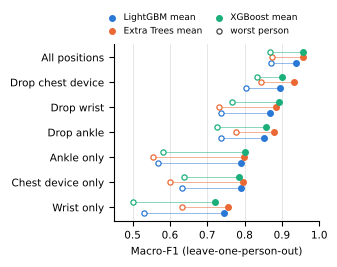

In [12]:
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 7.5, 'axes.spines.top': False, 'axes.spines.right': False})
COL = {'LightGBM': '#2a78d6', 'Extra Trees': '#eb6834', 'XGBoost': '#1baf7a'}
LABEL = {'all': 'All positions', 'drop chest device': 'Drop chest device', 'drop wrist': 'Drop wrist', 'drop ankle': 'Drop ankle',
         'only ankle': 'Ankle only', 'only chest device (acc + ECG)': 'Chest device only', 'only wrist': 'Wrist only'}
order = list(LABEL)[::-1]; yy = np.arange(len(order))
fig, ax = plt.subplots(figsize=(3.4, 2.7))
for j, (mname, col) in enumerate(COL.items()):
    s = pos_tab[pos_tab.model == mname].set_index('setting').loc[order]; off = (j - 1) * 0.22
    ax.scatter(s['mean'], yy + off, color=col, s=16, zorder=3, label=f'{mname} mean')
    ax.scatter(s['min'], yy + off, facecolors='white', edgecolors=col, s=14, linewidths=0.9, zorder=3)
    ax.hlines(yy + off, s['min'], s['mean'], color=col, lw=0.6, alpha=0.6)
ax.scatter([], [], facecolors='white', edgecolors='#555555', s=14, label='worst person')
ax.set_yticks(yy, [LABEL[o] for o in order]); ax.set_xlabel('Macro-F1 (leave-one-person-out)'); ax.set_xlim(0.45, 1.0)
ax.grid(axis='x', color='#dddddd', lw=0.5); ax.set_axisbelow(True)
ax.legend(loc='lower center', bbox_to_anchor=(0.42, 1.0), ncol=2, frameon=False, fontsize=6.5, handletextpad=0.3, columnspacing=0.8)
fig.tight_layout(); fig.savefig('report/fig_rq3_positions_3models.png', dpi=300, bbox_inches='tight'); plt.show()
plt.rcParams.update(plt.rcParamsDefault)

### 6b-6. Ổn định xếp hạng

- **Làm gì:** như bản nộp: cùng một phương pháp, mô hình học trên hai nhóm người không trùng nhau ({1, 2, 3} và {4, 5, 6, 7}), so hai xếp hạng bằng tương quan Spearman.
- **Kiểm tra:** `report/table_rq3_methods.csv`.

In [13]:
rA, _ = explain_all(fit_best(X_tr[GRP_A], y_tr[GRP_A], seed=1), X_tr, X_te, y_te)
rB, _ = explain_all(fit_best(X_tr[GRP_B], y_tr[GRP_B], seed=2), X_tr, X_te, y_te)
stab = pd.Series({k: spearmanr(rA[k][X_cols], rB[k][X_cols])[0] for k in rA}); print(stab.round(3))
pd.DataFrame({'rank_stability': stab, 'seconds': pd.Series(secs)}).to_csv('report/table_rq3_methods.csv')

TreeSHAP       0.542
KernelSHAP     0.565
LIME           0.465
Permutation    0.332
Gain           0.572
dtype: float64


## Bước 6c. Đối chiếu và bảng tham số

- **Làm gì:** đặt kết quả các phương pháp cạnh nhau, lưu hình SHAP và tham số mô hình.
- **Vì sao:** bảng tham số và danh sách đặc trưng đứng đầu đi vào phụ lục của bài.
- **Kiểm tra:** `report/params_best.json` tồn tại.

In [14]:
# Step 6c: what the methods say side by side, and the selected parameter table
import json, matplotlib.pyplot as plt
top = pd.DataFrame({k: r.index[:10] for k, r in ranks.items() if k != 'Random'})
top.to_csv('report/table_top10_by_method.csv', index=False); print(top.head(5))
votes = pd.Series([f for k, r in ranks.items() if k != 'Random' for f in r.index[:5]]).value_counts()
votes.rename('methods_listing_in_top5').to_csv('report/table_consensus_features.csv'); print(votes.head(8))
print(share.round(3))                                   # do the methods blame the same body position? (table_rq3_group_share.csv)
Xs = X_te.sample(min(500, len(X_te)), random_state=0)
shap.summary_plot(shap.TreeExplainer(best).shap_values(Xs), Xs, show=False, plot_type='bar')
plt.savefig('report/fig_shap.png', dpi=300, bbox_inches='tight'); plt.close()
with open('report/params_best.json', 'w', encoding='utf-8') as f: json.dump(best.get_params(), f, indent=2, default=str)   # parameter table

           TreeSHAP        KernelSHAP              LIME       Permutation  \
0  ankle_acc_y_mean  ankle_acc_y_mean  ankle_acc_y_mean  ankle_acc_y_mean   
1  chest_acc_x_mean  ankle_accmag_std  chest_acc_x_mean  ankle_accmag_std   
2  chest_acc_z_mean  chest_acc_x_mean  chest_acc_z_mean  chest_acc_x_mean   
3  ankle_accmag_std  chest_acc_z_mean  ankle_accmag_std  wrist_acc_y_mean   
4  wrist_acc_y_mean  wrist_accmag_std   ankle_acc_x_std  wrist_accmag_std   

                Gain  
0   chest_acc_z_mean  
1  ankle_accmag_mean  
2   ankle_acc_y_mean  
3   chest_acc_x_mean  
4   wrist_gyro_y_std  
ankle_acc_y_mean     5
chest_acc_x_mean     5
chest_acc_z_mean     4
ankle_accmag_std     4
wrist_acc_y_mean     2
wrist_accmag_std     2
ankle_acc_x_std      1
ankle_accmag_mean    1
Name: count, dtype: int64
              TreeSHAP  KernelSHAP   LIME  Permutation   Gain
ankle            0.399       0.422  0.401        0.506  0.338
chest            0.230       0.202  0.227        0.239  0.279
hea

/tmp/ipykernel_12396/2062056981.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap.TreeExplainer(best).shap_values(Xs), Xs, show=False, plot_type='bar')


## Test case và chẩn đoán

- **Làm gì:** kiểm tra tự động các sản phẩm của notebook.
- **Kiểm tra:** mọi `assert` qua. Sinh viên A chạy lại notebook này và ghi vào ô Đối chứng.

In [15]:
import glob
assert os.path.exists('report/table_rq2.csv') and os.path.exists('report/params_best.json')
assert all(os.path.exists('report/table_rq3_%s.csv' % t) for t in ['roar', 'roar_splits', 'roar_summary', 'group_share', 'methods', 'positions',
           'positions_folds', 'positions_tests', 'selection_baselines']), 'RQ3 tables missing'
assert os.path.exists('report/table_rq2_tests.csv') and os.path.exists('report/fig_rq3_positions_3models.png')
assert roar_rows.split.nunique() == 5 and set(roar_rows.model) == {'LightGBM', 'Extra Trees'}
assert pos.groupby(['model', 'setting']).size().eq(len(people) * len(SEEDS)).all(), 'every model and setting needs 10 people x 3 seeds'
assert res.macroF1.notna().all()
top = res.sort_values('macroF1').iloc[-1]
assert top.macroF1 > res.set_index('model').loc['Majority (naive)', 'macroF1'], 'the best model must beat the naive baseline'
print('best model', top.model, round(top.macroF1, 3), '+-', round(top.sd, 3))
print(sorted(os.path.basename(f) for f in glob.glob('report/*')))
print('Notebook B: all checks passed')

best model Extra Trees 0.962 +- 0.048
['fig_pipeline_overview.png', 'fig_pipeline_overview.svg', 'fig_pipeline_overview_cute.png', 'fig_pipeline_overview_cute.svg', 'fig_rq1.png', 'fig_rq2_models.png', 'fig_rq3_positions_3models.png', 'fig_shap.png', 'hardware.json', 'params_best.json', 'table_cleaning_log.csv', 'table_consensus_features.csv', 'table_diagnosis.csv', 'table_q1.csv', 'table_q2.csv', 'table_q3.csv', 'table_q5.csv', 'table_rq1_tests.csv', 'table_rq2.csv', 'table_rq2_folds.csv', 'table_rq2_tests.csv', 'table_rq3_group_share.csv', 'table_rq3_methods.csv', 'table_rq3_positions.csv', 'table_rq3_positions_folds.csv', 'table_rq3_positions_tests.csv', 'table_rq3_roar.csv', 'table_rq3_roar_splits.csv', 'table_rq3_roar_summary.csv', 'table_rq3_selection_baselines.csv', 'table_top10_by_method.csv']
Notebook B: all checks passed


### Đối chứng

| Người chạy lại | Ngày | Metric chính khớp | Ghi chú |
|---|---|---|---|
| | | | |

### Chẩn đoán

Nếu mô hình tốt nhất không hơn mốc đơn giản hoặc kết quả RQ3 trái dự kiến, ghi nguyên nhân có bằng chứng (thiếu đặc trưng, dữ liệu ít, lệch giữa hai tập) vào `report/table_diagnosis.csv`.

### Báo cáo tiến độ

1. Việc đã xong, kèm tên file và số dòng, bảng, hình:
2. Con số chính mới có:
3. Vướng mắc và điều đã thử:
4. Việc sẽ làm đến lần báo cáo sau, ai làm:
5. Prompt AI đáng chú ý và Human Delta: